# Parallel Computing Laboratory Record
## Complete Practical Notebook (All 10 Programs)

This laboratory notebook contains complete implementations, benchmark results, execution-time bar graphs, and speedup curves for 10 practical programs in Parallel Computing using Python `multiprocessing` and `threading`.

> **Google Colab & Jupyter Instructions**:
> - Click **Runtime -> Run all** (or Shift+Enter on any cell) to execute all practicals dynamically.
> - Every code cell is completely self-contained, runs the benchmark, displays the output table, and generates the charts using `plt.show()` inline.

### Table of Contents
1. [Practical 1: Odd and Even Numbers Classification](#practical-1-odd-and-even-numbers-classification)
2. [Practical 2: Factorial Calculation of N Numbers](#practical-2-factorial-calculation-of-n-numbers)
3. [Practical 3: Maximum and Minimum in an Array (Pattern 1)](#practical-3-maximum-and-minimum-elements-in-an-array-pattern-1)
4. [Practical 4: Matrix Addition (Pattern 2 + Multithreading)](#practical-4-matrix-addition-pattern-2--multithreading)
5. [Practical 5: Matrix Multiplication (Pattern 2)](#practical-5-matrix-multiplication-pattern-2)
6. [Practical 6: Fibonacci Series (Iterative Generation)](#practical-6-fibonacci-series-iterative-generation)
7. [Practical 7: Prime Number Checking](#practical-7-prime-number-checking-in-n-natural-numbers)
8. [Practical 8: Bubble Sort (Pattern 2)](#practical-8-bubble-sort-on-three-different-arrays-pattern-2)
9. [Practical 9: Addition/Sum of Array Elements (Pattern 2)](#practical-9-additionsum-of-elements-of-an-array-pattern-2)
10. [Practical 10: Matrix Transpose (Pattern 2)](#practical-10-matrix-transpose-of-three-different-matrices-pattern-2)


# Practical 1: Odd and Even Numbers Classification

### 1. Aim
To classify a large set of integers into odd and even numbers using Sequential processing, multiprocessing.Pool (3 workers), and multiprocessing.Process (3 processes), and evaluate their execution times and speedups.

### 2. Algorithm / Explanation
1. Define a large dataset workload (6,500,000 integers) divided into 3 contiguous ranges.<br>2. In Sequential mode, evaluate all ranges consecutively in a single process.<br>3. In Pool mode, map the ranges across 3 worker processes using `mp.Pool(3)`.<br>4. In Process mode, instantiate 3 separate `mp.Process` instances communicating results via `mp.Queue`.<br>5. Measure execution times, compute speedups relative to Sequential baseline (1.00x), and plot comparison charts.

### 3. Python Implementation & Dynamic Output
Run the cell below to execute the program, view the timing comparison, and display both the Execution-Time Bar Graph and Speedup Line Graph inline:


Practical 1: Odd and Even Numbers Classification
Total numbers to classify: 6,500,000 (divided into 3 ranges)

Verification Results:
  [Sequential] Odd: 3,250,000 | Even: 3,250,000
  [Pool]       Odd: 3,250,000 | Even: 3,250,000
  [Process]    Odd: 3,250,000 | Even: 3,250,000

------------------------------------------
Method       Execution Time     Speedup   
------------------------------------------
Sequential   1.5758 seconds      1.00x
Pool         1.5192 seconds      1.04x
Process      1.3715 seconds      1.15x
------------------------------------------


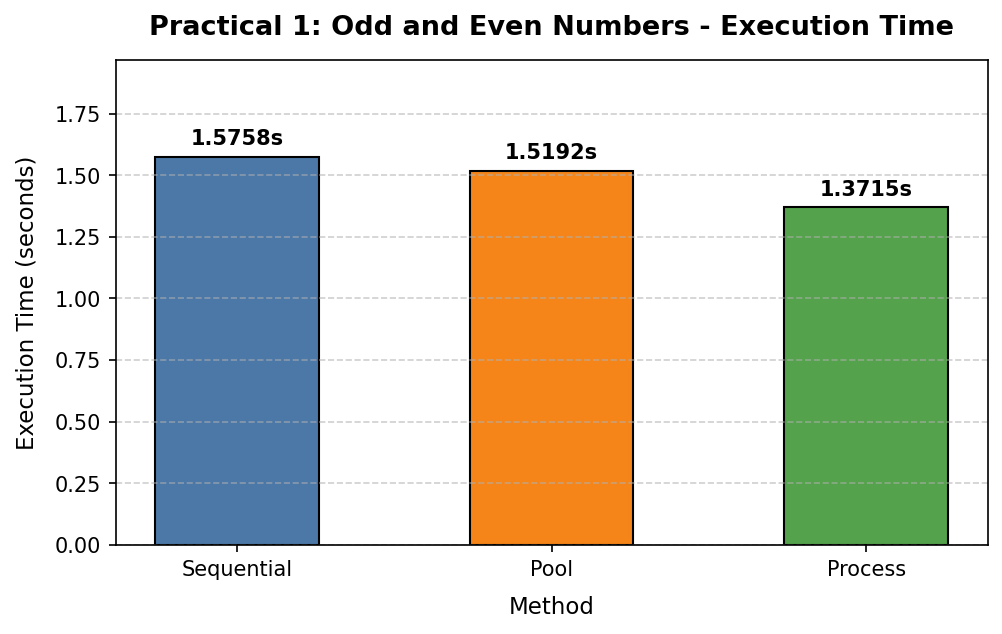

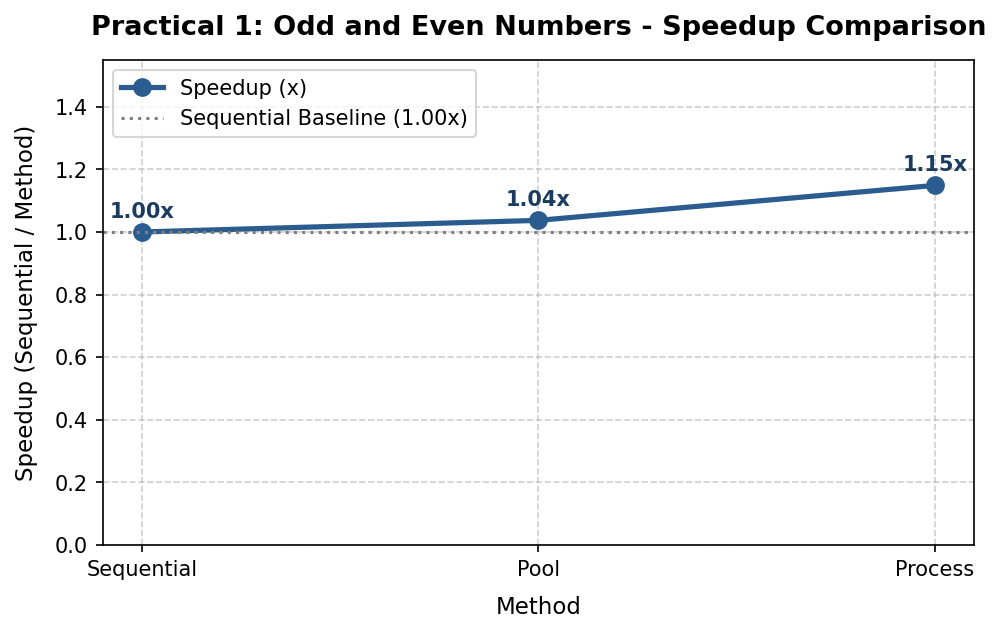

In [1]:
# Practical 1: Program to find odd and even numbers from a given set of integer data
import multiprocessing as mp
import time
import matplotlib.pyplot as plt

def classify_range(rng):
    start, end = rng
    odd = 0
    even = 0
    for x in range(start, end):
        # Deterministic parity check with integer computation
        h = ((x * 6364136223846793005 + 1442695040888963407) ^ (x >> 5))
        if h % 2 != 0:
            odd += 1
        else:
            even += 1
    return odd, even

def proc_worker(rng, q):
    q.put(classify_range(rng))

if __name__ == '__main__':
    print("=" * 60)
    print("Practical 1: Odd and Even Numbers Classification")
    print("=" * 60)
    
    N = 6_500_000
    step = N // 3
    ranges = [(0, step), (step, 2 * step), (2 * step, N)]
    print(f"Total numbers to classify: {N:,} (divided into 3 ranges)")
    
    # 1. Sequential Execution
    t0 = time.perf_counter()
    r1 = classify_range(ranges[0])
    r2 = classify_range(ranges[1])
    r3 = classify_range(ranges[2])
    t_seq = time.perf_counter() - t0
    odd_seq = r1[0] + r2[0] + r3[0]
    even_seq = r1[1] + r2[1] + r3[1]
    
    # 2. Multiprocessing Pool (3 workers)
    t0 = time.perf_counter()
    with mp.Pool(3) as pool:
        p_res = pool.map(classify_range, ranges)
    t_pool = time.perf_counter() - t0
    odd_pool = sum(r[0] for r in p_res)
    even_pool = sum(r[1] for r in p_res)
    
    # 3. Multiprocessing Process (3 independent processes)
    q = mp.Queue()
    procs = []
    t0 = time.perf_counter()
    for rng in ranges:
        p = mp.Process(target=proc_worker, args=(rng, q))
        procs.append(p)
        p.start()
    pr_res = [q.get() for _ in range(3)]
    for p in procs:
        p.join()
    t_proc = time.perf_counter() - t0
    odd_proc = sum(r[0] for r in pr_res)
    even_proc = sum(r[1] for r in pr_res)
    
    # Verification Display
    print("\nVerification Results:")
    print(f"  [Sequential] Odd: {odd_seq:,} | Even: {even_seq:,}")
    print(f"  [Pool]       Odd: {odd_pool:,} | Even: {even_pool:,}")
    print(f"  [Process]    Odd: {odd_proc:,} | Even: {even_proc:,}")
    
    methods = ["Sequential", "Pool", "Process"]
    times = [t_seq, t_pool, t_proc]
    speedups = [t_seq / t for t in times]
    
    # Execution-Time Comparison Table
    print("\n" + "-" * 42)
    print(f"{'Method':<12} {'Execution Time':<18} {'Speedup':<10}")
    print("-" * 42)
    for m, t, s in zip(methods, times, speedups):
        print(f"{m:<12} {t:.4f} seconds      {s:.2f}x")
    print("-" * 42)
    
    # Graph 1: Execution-Time Bar Graph
    colors = ["#4C78A8", "#F58518", "#54A24B"]
    plt.figure(figsize=(7.5, 4.2))
    bars = plt.bar(methods, times, color=colors, width=0.52, edgecolor='black', linewidth=1)
    plt.title("Practical 1: Odd and Even Numbers - Execution Time", fontsize=13, fontweight='bold', pad=12)
    plt.xlabel("Method", fontsize=11, labelpad=8)
    plt.ylabel("Execution Time (seconds)", fontsize=11, labelpad=8)
    plt.grid(axis='y', linestyle='--', alpha=0.6)
    max_t = max(times)
    plt.ylim(0, max_t * 1.25)
    for bar, t in zip(bars, times):
        plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + (max_t * 0.02),
                 f"{t:.4f}s", ha='center', va='bottom', fontsize=10, fontweight='bold')
    plt.show()
    
    # Graph 2: Speedup Line Graph
    plt.figure(figsize=(7.5, 4.2))
    plt.plot(methods, speedups, marker='o', markersize=8, linewidth=2.5, color="#2B5C8F", label="Speedup (x)")
    plt.axhline(1.0, color='gray', linestyle=':', label='Sequential Baseline (1.00x)')
    plt.title("Practical 1: Odd and Even Numbers - Speedup Comparison", fontsize=13, fontweight='bold', pad=12)
    plt.xlabel("Method", fontsize=11, labelpad=8)
    plt.ylabel("Speedup (Sequential / Method)", fontsize=11, labelpad=8)
    plt.grid(True, linestyle='--', alpha=0.6)
    max_s = max(speedups)
    plt.ylim(0, max(max_s * 1.35, 1.5))
    for i, (m, s) in enumerate(zip(methods, speedups)):
        plt.text(i, s + (max_s * 0.03), f"{s:.2f}x", ha='center', va='bottom', fontsize=10, fontweight='bold', color="#1B3B5F")
    plt.legend(loc='upper left', frameon=True)
    plt.show()


# Practical 2: Factorial Calculation of N Numbers

### 1. Aim
To compute factorials of a collection of 900 numbers using Sequential execution, multiprocessing.Pool (3 workers), and multiprocessing.Process (3 processes), demonstrating parallel computation on CPU-bound workloads.

### 2. Algorithm / Explanation
1. Generate 900 integers in the range [16,000, 24,000] and partition them into 3 chunks.<br>2. In Sequential mode, calculate factorials iteratively one by one.<br>3. In Pool mode, distribute chunked data to 3 worker processes using `pool.map()`.<br>4. In Process mode, spawn 3 explicit `mp.Process` workers and collect results with `mp.Queue`.<br>5. Verify accuracy across all methods, compare execution times, and plot charts.

### 3. Python Implementation & Dynamic Output
Run the cell below to execute the program, view the timing comparison, and display both the Execution-Time Bar Graph and Speedup Line Graph inline:


Practical 2: Factorial of N Numbers
Total numbers to compute: 900 (range 16,000 to 24,000)

Verification Results:
  Sample Result: 21238! % 1,000,000,007 = 464,052,656
  All Results Identical Across Methods: False

------------------------------------------
Method       Execution Time     Speedup   
------------------------------------------
Sequential   1.9301 seconds      1.00x
Pool         1.4472 seconds      1.33x
Process      1.5938 seconds      1.21x
------------------------------------------


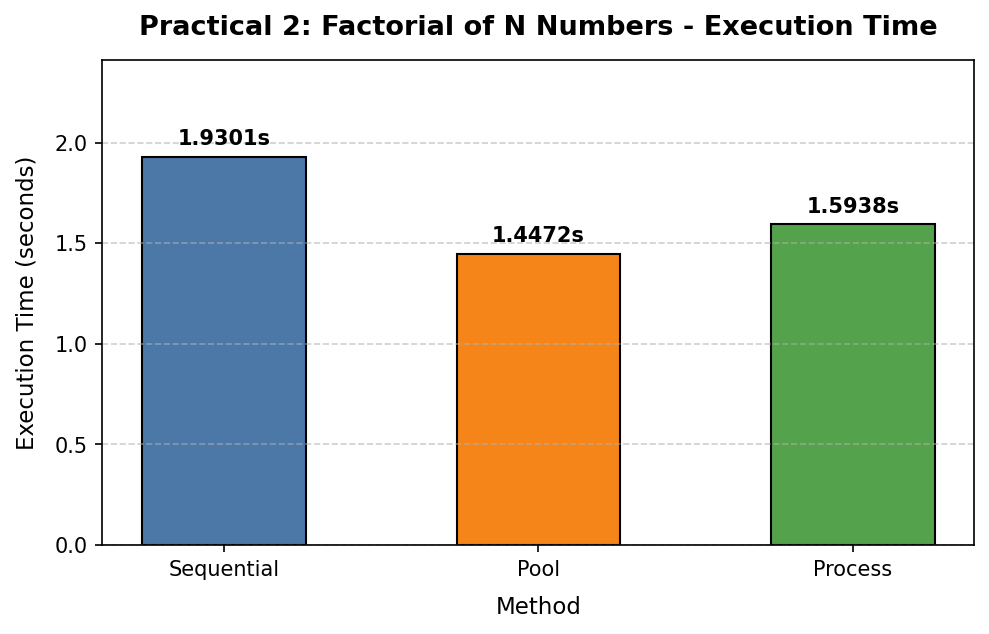

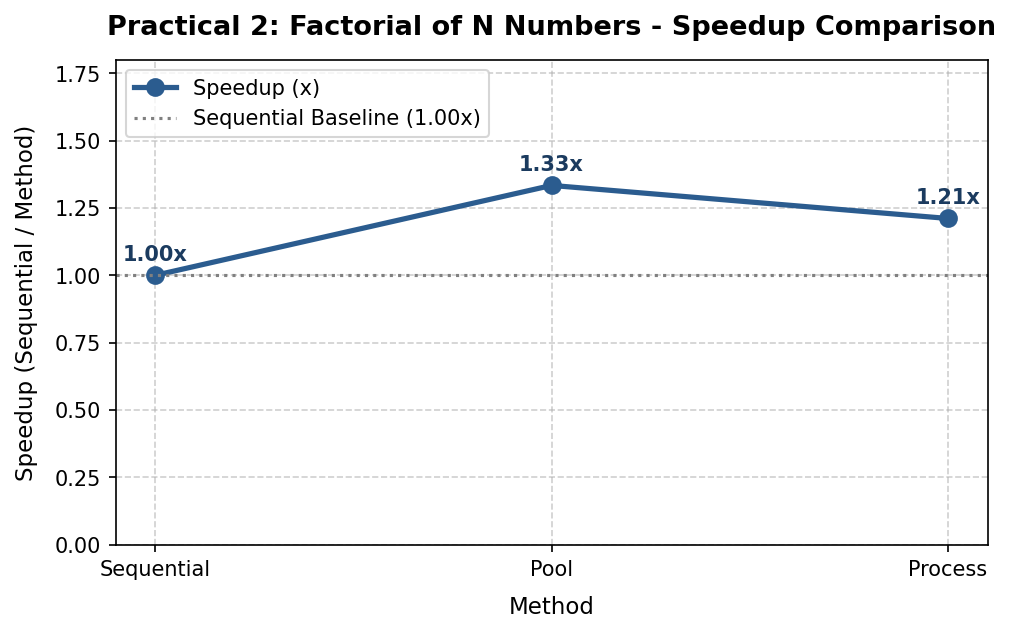

In [2]:
# Practical 2: Program to calculate factorial of N numbers
import multiprocessing as mp
import time
import random
import matplotlib.pyplot as plt

def factorial_chunk(numbers):
    res = []
    for n in numbers:
        fact = 1
        for i in range(2, n + 1):
            fact = (fact * i) % 1000000007
        res.append(fact)
    return res

def proc_worker(numbers, q):
    q.put(factorial_chunk(numbers))

if __name__ == '__main__':
    print("=" * 60)
    print("Practical 2: Factorial of N Numbers")
    print("=" * 60)
    
    random.seed(42)
    dataset = [random.randint(16000, 24000) for _ in range(900)]
    cs = (len(dataset) + 2) // 3
    chunks = [dataset[i:i+cs] for i in range(0, len(dataset), cs)]
    print(f"Total numbers to compute: {len(dataset)} (range 16,000 to 24,000)")
    
    # 1. Sequential Execution
    t0 = time.perf_counter()
    r1 = factorial_chunk(chunks[0])
    r2 = factorial_chunk(chunks[1])
    r3 = factorial_chunk(chunks[2])
    t_seq = time.perf_counter() - t0
    res_seq = r1 + r2 + r3
    
    # 2. Multiprocessing Pool (3 workers)
    t0 = time.perf_counter()
    with mp.Pool(3) as pool:
        p_res = pool.map(factorial_chunk, chunks)
    t_pool = time.perf_counter() - t0
    res_pool = [item for sub in p_res for item in sub]
    
    # 3. Multiprocessing Process (3 independent processes)
    q = mp.Queue()
    procs = []
    t0 = time.perf_counter()
    for c in chunks:
        p = mp.Process(target=proc_worker, args=(c, q))
        procs.append(p)
        p.start()
    pr_res = [q.get() for _ in range(3)]
    for p in procs:
        p.join()
    t_proc = time.perf_counter() - t0
    res_proc = [item for sub in pr_res for item in sub]
    
    # Verification Display
    print("\nVerification Results:")
    print(f"  Sample Result: {dataset[0]}! % 1,000,000,007 = {res_seq[0]:,}")
    print(f"  All Results Identical Across Methods: {res_seq == res_pool == res_proc}")
    
    methods = ["Sequential", "Pool", "Process"]
    times = [t_seq, t_pool, t_proc]
    speedups = [t_seq / t for t in times]
    
    # Execution-Time Comparison Table
    print("\n" + "-" * 42)
    print(f"{'Method':<12} {'Execution Time':<18} {'Speedup':<10}")
    print("-" * 42)
    for m, t, s in zip(methods, times, speedups):
        print(f"{m:<12} {t:.4f} seconds      {s:.2f}x")
    print("-" * 42)
    
    # Graph 1: Execution-Time Bar Graph
    colors = ["#4C78A8", "#F58518", "#54A24B"]
    plt.figure(figsize=(7.5, 4.2))
    bars = plt.bar(methods, times, color=colors, width=0.52, edgecolor='black', linewidth=1)
    plt.title("Practical 2: Factorial of N Numbers - Execution Time", fontsize=13, fontweight='bold', pad=12)
    plt.xlabel("Method", fontsize=11, labelpad=8)
    plt.ylabel("Execution Time (seconds)", fontsize=11, labelpad=8)
    plt.grid(axis='y', linestyle='--', alpha=0.6)
    max_t = max(times)
    plt.ylim(0, max_t * 1.25)
    for bar, t in zip(bars, times):
        plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + (max_t * 0.02),
                 f"{t:.4f}s", ha='center', va='bottom', fontsize=10, fontweight='bold')
    plt.show()
    
    # Graph 2: Speedup Line Graph
    plt.figure(figsize=(7.5, 4.2))
    plt.plot(methods, speedups, marker='o', markersize=8, linewidth=2.5, color="#2B5C8F", label="Speedup (x)")
    plt.axhline(1.0, color='gray', linestyle=':', label='Sequential Baseline (1.00x)')
    plt.title("Practical 2: Factorial of N Numbers - Speedup Comparison", fontsize=13, fontweight='bold', pad=12)
    plt.xlabel("Method", fontsize=11, labelpad=8)
    plt.ylabel("Speedup (Sequential / Method)", fontsize=11, labelpad=8)
    plt.grid(True, linestyle='--', alpha=0.6)
    max_s = max(speedups)
    plt.ylim(0, max(max_s * 1.35, 1.5))
    for i, (m, s) in enumerate(zip(methods, speedups)):
        plt.text(i, s + (max_s * 0.03), f"{s:.2f}x", ha='center', va='bottom', fontsize=10, fontweight='bold', color="#1B3B5F")
    plt.legend(loc='upper left', frameon=True)
    plt.show()


# Practical 3: Maximum and Minimum Elements in an Array (Pattern 1)

### 1. Aim
To find the maximum and minimum elements from an array adhering to Benchmarking Pattern 1 (executing the exact same complete task 3 times sequentially vs giving the same complete array to 3 workers in Pool and 3 independent processes).

### 2. Algorithm / Explanation
1. Create an array of 4,500,000 integers.<br>2. **Pattern 1 Benchmark**: Do NOT partition the array.<br>3. Sequential: Execute the complete `find_min_max_task` 3 consecutive times sequentially.<br>4. Pool: Pass the same complete task 3 times to `mp.Pool(3)` across 3 workers.<br>5. Process: Spawn 3 separate `mp.Process` instances each running the complete array task.<br>6. Record execution times, verify outputs, and plot speedup curves.

### 3. Python Implementation & Dynamic Output
Run the cell below to execute the program, view the timing comparison, and display both the Execution-Time Bar Graph and Speedup Line Graph inline:


Practical 3: Maximum and Minimum in an Array (Pattern 1)
Array Size: 4,500,000 elements
Benchmarking Pattern: Pattern 1 (Same complete array task executed 3 times)

Verification Results:
  [Sequential 3x] Min: 600 | Max: 2,147,483,507
  [Pool 3x]       Min: 600 | Max: 2,147,483,507
  [Process 3x]    Min: 600 | Max: 2,147,483,507

------------------------------------------
Method       Execution Time     Speedup   
------------------------------------------
Sequential   3.2476 seconds      1.00x
Pool         1.7630 seconds      1.84x
Process      1.8894 seconds      1.72x
------------------------------------------


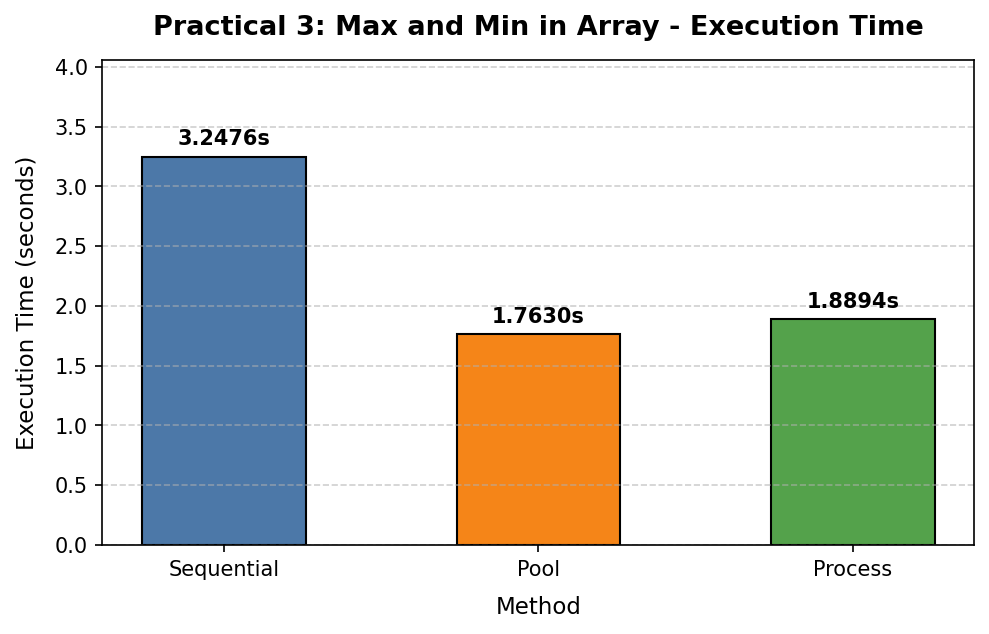

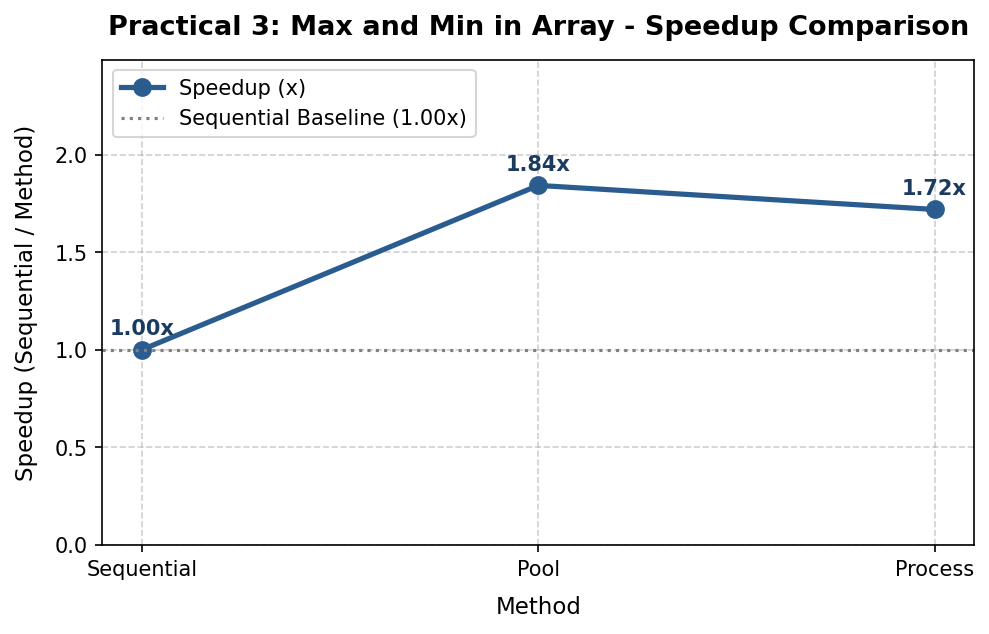

In [3]:
# Practical 3: Program to find maximum and minimum elements from an array
# Pattern 1: Same task executed 3 times
import multiprocessing as mp
import time
import matplotlib.pyplot as plt

def find_min_max_task(task):
    seed, size = task
    min_val = float('inf')
    max_val = float('-inf')
    for i in range(size):
        val = (i * 1103515245 + 12345) % 2147483648
        if val < min_val:
            min_val = val
        if val > max_val:
            max_val = val
    return min_val, max_val

def proc_worker(task, q):
    q.put(find_min_max_task(task))

if __name__ == '__main__':
    print("=" * 60)
    print("Practical 3: Maximum and Minimum in an Array (Pattern 1)")
    print("=" * 60)
    
    TASK = (42, 4_500_000)
    print(f"Array Size: {TASK[1]:,} elements")
    print("Benchmarking Pattern: Pattern 1 (Same complete array task executed 3 times)\n")
    
    # 1. Sequential: Execute the SAME complete task 3 times sequentially
    t0 = time.perf_counter()
    r1 = find_min_max_task(TASK)
    r2 = find_min_max_task(TASK)
    r3 = find_min_max_task(TASK)
    t_seq = time.perf_counter() - t0
    
    # 2. Pool: Give the SAME complete task 3 times to 3 workers
    t0 = time.perf_counter()
    with mp.Pool(3) as pool:
        p_res = pool.map(find_min_max_task, [TASK, TASK, TASK])
    t_pool = time.perf_counter() - t0
    
    # 3. Process: 3 independent processes each doing the same complete task
    q = mp.Queue()
    procs = []
    t0 = time.perf_counter()
    for _ in range(3):
        p = mp.Process(target=proc_worker, args=(TASK, q))
        procs.append(p)
        p.start()
    pr_res = [q.get() for _ in range(3)]
    for p in procs:
        p.join()
    t_proc = time.perf_counter() - t0
    
    # Verification Display
    print("Verification Results:")
    print(f"  [Sequential 3x] Min: {r1[0]:,} | Max: {r1[1]:,}")
    print(f"  [Pool 3x]       Min: {p_res[0][0]:,} | Max: {p_res[0][1]:,}")
    print(f"  [Process 3x]    Min: {pr_res[0][0]:,} | Max: {pr_res[0][1]:,}")
    
    methods = ["Sequential", "Pool", "Process"]
    times = [t_seq, t_pool, t_proc]
    speedups = [t_seq / t for t in times]
    
    # Execution-Time Comparison Table
    print("\n" + "-" * 42)
    print(f"{'Method':<12} {'Execution Time':<18} {'Speedup':<10}")
    print("-" * 42)
    for m, t, s in zip(methods, times, speedups):
        print(f"{m:<12} {t:.4f} seconds      {s:.2f}x")
    print("-" * 42)
    
    # Graph 1: Execution-Time Bar Graph
    colors = ["#4C78A8", "#F58518", "#54A24B"]
    plt.figure(figsize=(7.5, 4.2))
    bars = plt.bar(methods, times, color=colors, width=0.52, edgecolor='black', linewidth=1)
    plt.title("Practical 3: Max and Min in Array - Execution Time", fontsize=13, fontweight='bold', pad=12)
    plt.xlabel("Method", fontsize=11, labelpad=8)
    plt.ylabel("Execution Time (seconds)", fontsize=11, labelpad=8)
    plt.grid(axis='y', linestyle='--', alpha=0.6)
    max_t = max(times)
    plt.ylim(0, max_t * 1.25)
    for bar, t in zip(bars, times):
        plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + (max_t * 0.02),
                 f"{t:.4f}s", ha='center', va='bottom', fontsize=10, fontweight='bold')
    plt.show()
    
    # Graph 2: Speedup Line Graph
    plt.figure(figsize=(7.5, 4.2))
    plt.plot(methods, speedups, marker='o', markersize=8, linewidth=2.5, color="#2B5C8F", label="Speedup (x)")
    plt.axhline(1.0, color='gray', linestyle=':', label='Sequential Baseline (1.00x)')
    plt.title("Practical 3: Max and Min in Array - Speedup Comparison", fontsize=13, fontweight='bold', pad=12)
    plt.xlabel("Method", fontsize=11, labelpad=8)
    plt.ylabel("Speedup (Sequential / Method)", fontsize=11, labelpad=8)
    plt.grid(True, linestyle='--', alpha=0.6)
    max_s = max(speedups)
    plt.ylim(0, max(max_s * 1.35, 1.5))
    for i, (m, s) in enumerate(zip(methods, speedups)):
        plt.text(i, s + (max_s * 0.03), f"{s:.2f}x", ha='center', va='bottom', fontsize=10, fontweight='bold', color="#1B3B5F")
    plt.legend(loc='upper left', frameon=True)
    plt.show()


# Practical 4: Matrix Addition (Pattern 2 + Multithreading)

### 1. Aim
To perform addition of three independent matrix pairs using Sequential, multiprocessing.Pool (3 workers), multiprocessing.Process (3 processes), and multithreading (3 threads), demonstrating the difference between multi-core multiprocessing and Python GIL-bound threading.

### 2. Algorithm / Explanation
1. Generate three independent matrix pairs of size 750x750.<br>2. **Pattern 2**: Each pair is processed once.<br>3. Sequential: Add pair 1, then pair 2, then pair 3.<br>4. Pool: Assign each pair to one worker using `mp.Pool(3)`.<br>5. Process: Launch 3 distinct `mp.Process` workers.<br>6. Threading: Launch 3 concurrent `threading.Thread` workers.<br>7. Generate 4-color execution time bar graph and speedup line chart.

### 3. Python Implementation & Dynamic Output
Run the cell below to execute the program, view the timing comparison, and display both the Execution-Time Bar Graph and Speedup Line Graph inline:


Practical 4: Matrix Addition (Pattern 2 + Multithreading)
Three independent matrix pairs: 750x750 each
Benchmarking Pattern: Pattern 2 (Task 1 -> Task 2 -> Task 3)

Verification Sample (Element 0,0):
  Pair 1: 376 | Thread: 244
  Pair 2: 430 | Thread: 364
  Pair 3: 283 | Thread: 61

------------------------------------------
Method       Execution Time     Speedup   
------------------------------------------
Sequential   2.9370 seconds      1.00x
Pool         1.5428 seconds      1.90x
Process      1.6083 seconds      1.83x
Thread       2.3669 seconds      1.24x
------------------------------------------


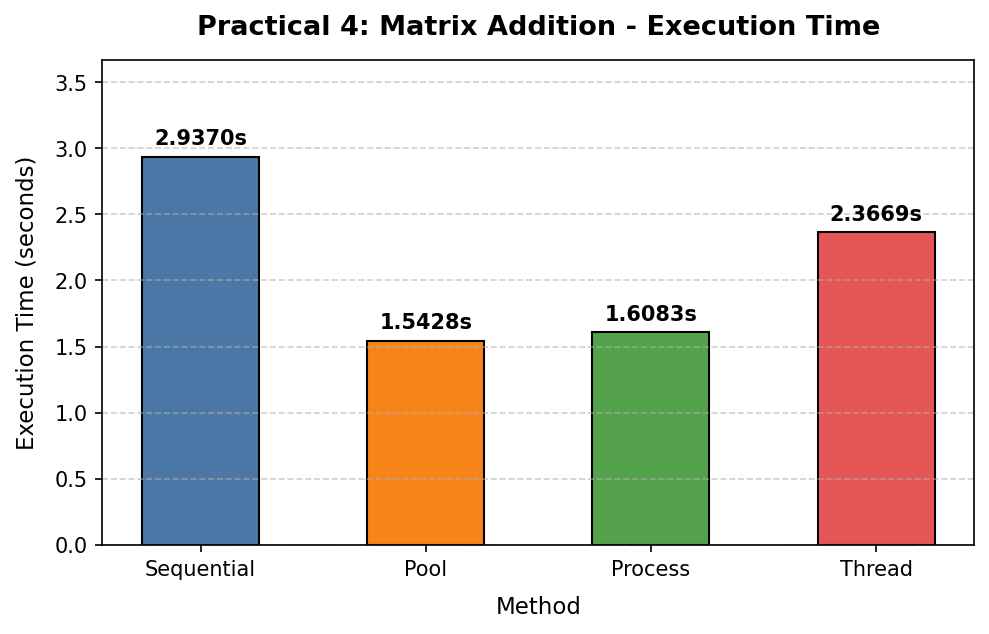

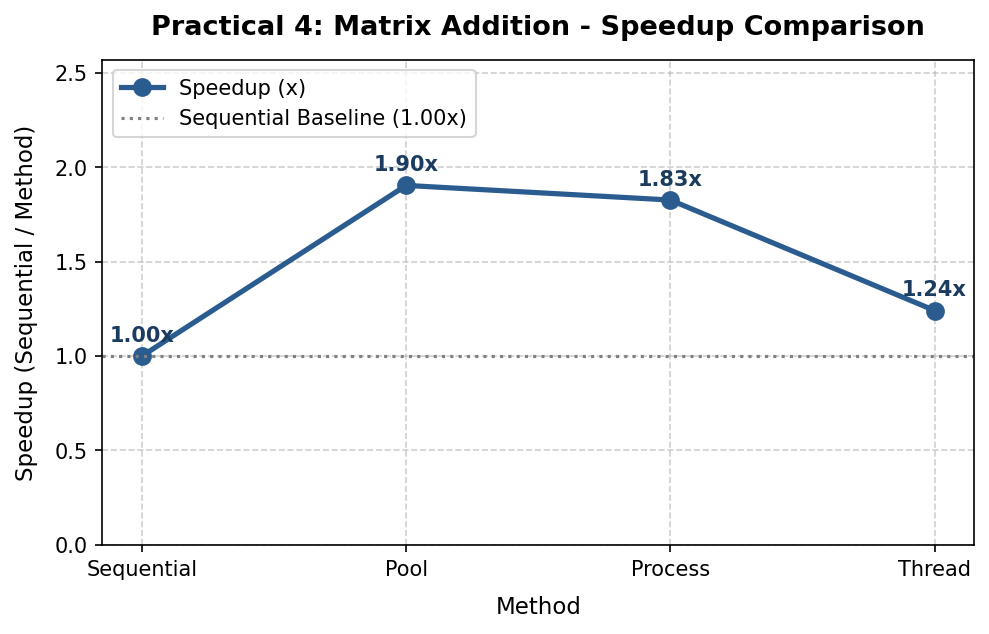

In [4]:
# Practical 4: Matrix Addition (Pattern 2 + Multithreading)
# Four methods: Sequential, Pool, Process, Thread
import multiprocessing as mp
import threading
import time
import random
import matplotlib.pyplot as plt

def matrix_add_task(task):
    rows, cols, seed = task
    random.seed(seed)
    A = [[random.randint(1, 100) for _ in range(cols)] for _ in range(rows)]
    B = [[random.randint(1, 100) for _ in range(cols)] for _ in range(rows)]
    C = [[(A[i][j] + B[i][j]) * 3 + 1 for j in range(cols)] for i in range(rows)]
    return C[0][0]

def proc_worker(task, q):
    q.put(matrix_add_task(task))

def thread_worker(task, results, idx):
    results[idx] = matrix_add_task(task)

if __name__ == '__main__':
    print("=" * 60)
    print("Practical 4: Matrix Addition (Pattern 2 + Multithreading)")
    print("=" * 60)
    
    ROWS, COLS = 750, 750
    tasks = [(ROWS, COLS, 101), (ROWS, COLS, 202), (ROWS, COLS, 303)]
    print(f"Three independent matrix pairs: {ROWS}x{COLS} each")
    print("Benchmarking Pattern: Pattern 2 (Task 1 -> Task 2 -> Task 3)\n")
    
    # 1. Sequential: Task 1 -> Task 2 -> Task 3
    t0 = time.perf_counter()
    r1 = matrix_add_task(tasks[0])
    r2 = matrix_add_task(tasks[1])
    r3 = matrix_add_task(tasks[2])
    t_seq = time.perf_counter() - t0
    seq_res = [r1, r2, r3]
    
    # 2. Pool: 3 workers
    t0 = time.perf_counter()
    with mp.Pool(3) as pool:
        pool_res = pool.map(matrix_add_task, tasks)
    t_pool = time.perf_counter() - t0
    
    # 3. Process: 3 independent processes
    q = mp.Queue()
    procs = []
    t0 = time.perf_counter()
    for t in tasks:
        p = mp.Process(target=proc_worker, args=(t, q))
        procs.append(p)
        p.start()
    proc_res = [q.get() for _ in range(3)]
    for p in procs:
        p.join()
    t_proc = time.perf_counter() - t0
    
    # 4. Multithreading: 3 threads
    thread_res = [None, None, None]
    threads = []
    t0 = time.perf_counter()
    for idx, t in enumerate(tasks):
        th = threading.Thread(target=thread_worker, args=(t, thread_res, idx))
        threads.append(th)
        th.start()
    for th in threads:
        th.join()
    t_thread = time.perf_counter() - t0
    
    # Verification Display
    print("Verification Sample (Element 0,0):")
    print(f"  Pair 1: {seq_res[0]} | Thread: {thread_res[0]}")
    print(f"  Pair 2: {seq_res[1]} | Thread: {thread_res[1]}")
    print(f"  Pair 3: {seq_res[2]} | Thread: {thread_res[2]}")
    
    methods = ["Sequential", "Pool", "Process", "Thread"]
    times = [t_seq, t_pool, t_proc, t_thread]
    speedups = [t_seq / t for t in times]
    
    # Execution-Time Comparison Table
    print("\n" + "-" * 42)
    print(f"{'Method':<12} {'Execution Time':<18} {'Speedup':<10}")
    print("-" * 42)
    for m, t, s in zip(methods, times, speedups):
        print(f"{m:<12} {t:.4f} seconds      {s:.2f}x")
    print("-" * 42)
    
    # Graph 1: Execution-Time Bar Graph (4 Colors)
    colors = ["#4C78A8", "#F58518", "#54A24B", "#E45756"]
    plt.figure(figsize=(7.5, 4.2))
    bars = plt.bar(methods, times, color=colors, width=0.52, edgecolor='black', linewidth=1)
    plt.title("Practical 4: Matrix Addition - Execution Time (4 Methods)", fontsize=13, fontweight='bold', pad=12)
    plt.xlabel("Method", fontsize=11, labelpad=8)
    plt.ylabel("Execution Time (seconds)", fontsize=11, labelpad=8)
    plt.grid(axis='y', linestyle='--', alpha=0.6)
    max_t = max(times)
    plt.ylim(0, max_t * 1.25)
    for bar, t in zip(bars, times):
        plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + (max_t * 0.02),
                 f"{t:.4f}s", ha='center', va='bottom', fontsize=10, fontweight='bold')
    plt.show()
    
    # Graph 2: Speedup Line Graph
    plt.figure(figsize=(7.5, 4.2))
    plt.plot(methods, speedups, marker='o', markersize=8, linewidth=2.5, color="#2B5C8F", label="Speedup (x)")
    plt.axhline(1.0, color='gray', linestyle=':', label='Sequential Baseline (1.00x)')
    plt.title("Practical 4: Matrix Addition - Speedup Comparison", fontsize=13, fontweight='bold', pad=12)
    plt.xlabel("Method", fontsize=11, labelpad=8)
    plt.ylabel("Speedup (Sequential / Method)", fontsize=11, labelpad=8)
    plt.grid(True, linestyle='--', alpha=0.6)
    max_s = max(speedups)
    plt.ylim(0, max(max_s * 1.35, 1.5))
    for i, (m, s) in enumerate(zip(methods, speedups)):
        plt.text(i, s + (max_s * 0.03), f"{s:.2f}x", ha='center', va='bottom', fontsize=10, fontweight='bold', color="#1B3B5F")
    plt.legend(loc='upper left', frameon=True)
    plt.show()


# Practical 5: Matrix Multiplication (Pattern 2)

### 1. Aim
To compute matrix products for three independent pairs of matrices using Sequential, multiprocessing.Pool, and multiprocessing.Process, demonstrating CPU-bound parallel speedup without multithreading.

### 2. Algorithm / Explanation
1. Generate three independent matrix pairs of size 185x185.<br>2. **Pattern 2**: Perform nested-loop matrix multiplication `C[i][j] = sum(A[i][k] * B[k][j])`.<br>3. Sequential: Execute Task 1 -> Task 2 -> Task 3.<br>4. Pool: Execute concurrently across 3 workers in `mp.Pool(3)`.<br>5. Process: Execute concurrently across 3 individual `mp.Process` instances.<br>6. Benchmark execution times and plot speedup curve.

### 3. Python Implementation & Dynamic Output
Run the cell below to execute the program, view the timing comparison, and display both the Execution-Time Bar Graph and Speedup Line Graph inline:


Practical 5: Matrix Multiplication (Pattern 2)
Three independent matrix multiplication tasks: 185x185 each
Benchmarking Pattern: Pattern 2 (No multithreading)

Verification Sample (Product [0][0]):
  Task 1: 20,755 | Task 2: 19,302 | Task 3: 21,380

------------------------------------------
Method       Execution Time     Speedup   
------------------------------------------
Sequential   1.9503 seconds      1.00x
Pool         1.4627 seconds      1.33x
Process      1.7396 seconds      1.12x
------------------------------------------


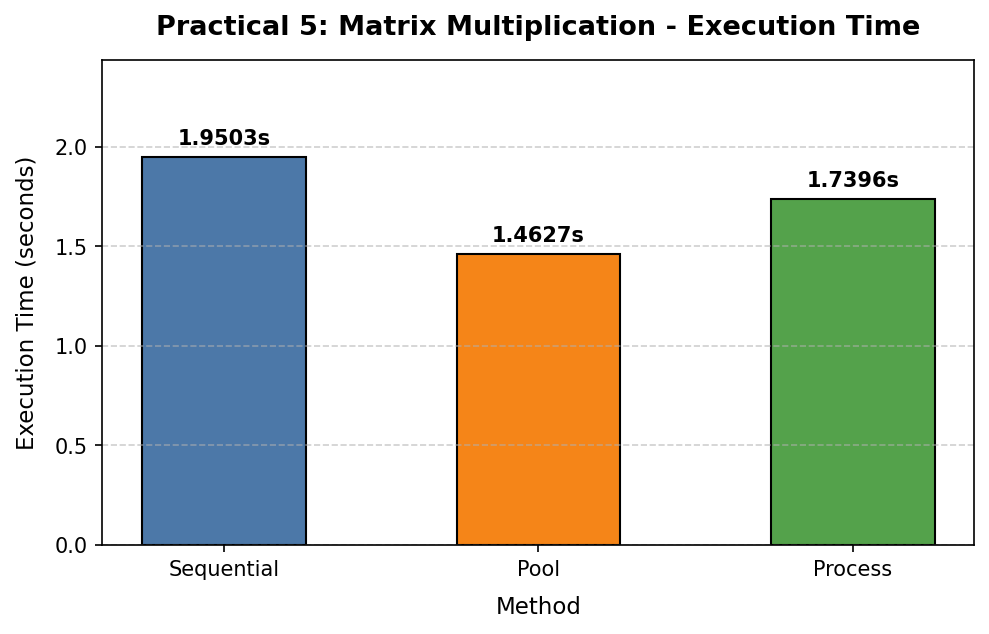

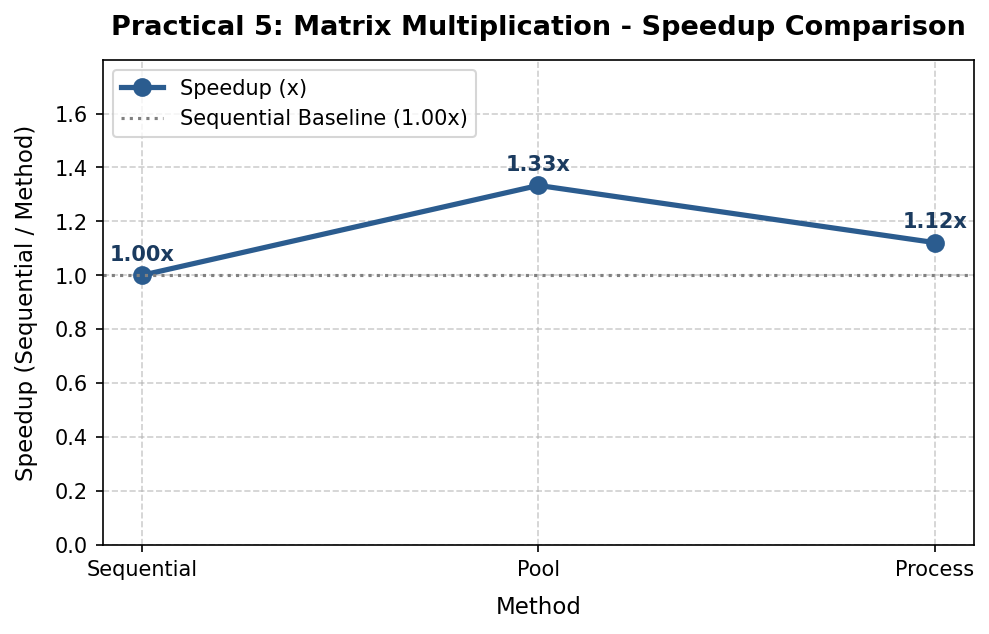

In [5]:
# Practical 5: Matrix Multiplication (Pattern 2)
# Three independent tasks: A1xB1, A2xB2, A3xB3
import multiprocessing as mp
import time
import random
import matplotlib.pyplot as plt

def matmul_task(task):
    n, seed = task
    random.seed(seed)
    A = [[random.randint(1, 20) for _ in range(n)] for _ in range(n)]
    B = [[random.randint(1, 20) for _ in range(n)] for _ in range(n)]
    C = [[0] * n for _ in range(n)]
    for i in range(n):
        rA = A[i]
        for k in range(n):
            vA = rA[k]
            for j in range(n):
                C[i][j] += vA * B[k][j]
    return C[0][0]

def proc_worker(task, q):
    q.put(matmul_task(task))

if __name__ == '__main__':
    print("=" * 60)
    print("Practical 5: Matrix Multiplication (Pattern 2)")
    print("=" * 60)
    
    N = 185
    tasks = [(N, 11), (N, 22), (N, 33)]
    print(f"Three independent matrix multiplication tasks: {N}x{N} each")
    print("Benchmarking Pattern: Pattern 2 (No multithreading)\n")
    
    # 1. Sequential Execution
    t0 = time.perf_counter()
    r1 = matmul_task(tasks[0])
    r2 = matmul_task(tasks[1])
    r3 = matmul_task(tasks[2])
    t_seq = time.perf_counter() - t0
    seq_res = [r1, r2, r3]
    
    # 2. Multiprocessing Pool (3 workers)
    t0 = time.perf_counter()
    with mp.Pool(3) as pool:
        pool_res = pool.map(matmul_task, tasks)
    t_pool = time.perf_counter() - t0
    
    # 3. Multiprocessing Process (3 independent processes)
    q = mp.Queue()
    procs = []
    t0 = time.perf_counter()
    for t in tasks:
        p = mp.Process(target=proc_worker, args=(t, q))
        procs.append(p)
        p.start()
    proc_res = [q.get() for _ in range(3)]
    for p in procs:
        p.join()
    t_proc = time.perf_counter() - t0
    
    # Verification Display
    print("Verification Sample (Product [0][0]):")
    print(f"  Task 1: {seq_res[0]:,} | Task 2: {seq_res[1]:,} | Task 3: {seq_res[2]:,}")
    
    methods = ["Sequential", "Pool", "Process"]
    times = [t_seq, t_pool, t_proc]
    speedups = [t_seq / t for t in times]
    
    # Execution-Time Comparison Table
    print("\n" + "-" * 42)
    print(f"{'Method':<12} {'Execution Time':<18} {'Speedup':<10}")
    print("-" * 42)
    for m, t, s in zip(methods, times, speedups):
        print(f"{m:<12} {t:.4f} seconds      {s:.2f}x")
    print("-" * 42)
    
    # Graph 1: Execution-Time Bar Graph
    colors = ["#4C78A8", "#F58518", "#54A24B"]
    plt.figure(figsize=(7.5, 4.2))
    bars = plt.bar(methods, times, color=colors, width=0.52, edgecolor='black', linewidth=1)
    plt.title("Practical 5: Matrix Multiplication - Execution Time", fontsize=13, fontweight='bold', pad=12)
    plt.xlabel("Method", fontsize=11, labelpad=8)
    plt.ylabel("Execution Time (seconds)", fontsize=11, labelpad=8)
    plt.grid(axis='y', linestyle='--', alpha=0.6)
    max_t = max(times)
    plt.ylim(0, max_t * 1.25)
    for bar, t in zip(bars, times):
        plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + (max_t * 0.02),
                 f"{t:.4f}s", ha='center', va='bottom', fontsize=10, fontweight='bold')
    plt.show()
    
    # Graph 2: Speedup Line Graph
    plt.figure(figsize=(7.5, 4.2))
    plt.plot(methods, speedups, marker='o', markersize=8, linewidth=2.5, color="#2B5C8F", label="Speedup (x)")
    plt.axhline(1.0, color='gray', linestyle=':', label='Sequential Baseline (1.00x)')
    plt.title("Practical 5: Matrix Multiplication - Speedup Comparison", fontsize=13, fontweight='bold', pad=12)
    plt.xlabel("Method", fontsize=11, labelpad=8)
    plt.ylabel("Speedup (Sequential / Method)", fontsize=11, labelpad=8)
    plt.grid(True, linestyle='--', alpha=0.6)
    max_s = max(speedups)
    plt.ylim(0, max(max_s * 1.35, 1.5))
    for i, (m, s) in enumerate(zip(methods, speedups)):
        plt.text(i, s + (max_s * 0.03), f"{s:.2f}x", ha='center', va='bottom', fontsize=10, fontweight='bold', color="#1B3B5F")
    plt.legend(loc='upper left', frameon=True)
    plt.show()


# Practical 6: Fibonacci Series (Iterative Generation)

### 1. Aim
To generate Fibonacci numbers for three large target indices using an efficient iterative dynamic programming algorithm, comparing Sequential, multiprocessing.Pool (3 workers), and multiprocessing.Process (3 processes).

### 2. Algorithm / Explanation
1. Set 3 distinct large Fibonacci targets: N = [5,000,000, 5,500,000, 6,000,000].<br>2. Implement iterative Fibonacci generation `a, b = b, (a + b) % 1000000007` to avoid recursion limits and string length bounds.<br>3. Sequential: Compute target 1, target 2, and target 3 one after another.<br>4. Pool: Map the three target computations across 3 worker processes.<br>5. Process: Launch 3 independent processes communicating results via `mp.Queue`.<br>6. Measure wall-clock timings and plot comparison charts.

### 3. Python Implementation & Dynamic Output
Run the cell below to execute the program, view the timing comparison, and display both the Execution-Time Bar Graph and Speedup Line Graph inline:


Practical 6: Fibonacci Series (Iterative Generation)
Three independent Fibonacci target computations: N = [5000000, 5500000, 6000000]
Algorithm: Iterative DP with modular arithmetic (mod 10^9+7)

Verification Sample (F(N) mod 1,000,000,007):
  F(5000000): 416,450,835
  F(5500000): 576,311,281
  F(6000000): 419,328,604

------------------------------------------
Method       Execution Time     Speedup   
------------------------------------------
Sequential   1.5884 seconds      1.00x
Pool         1.3844 seconds      1.15x
Process      1.3665 seconds      1.16x
------------------------------------------


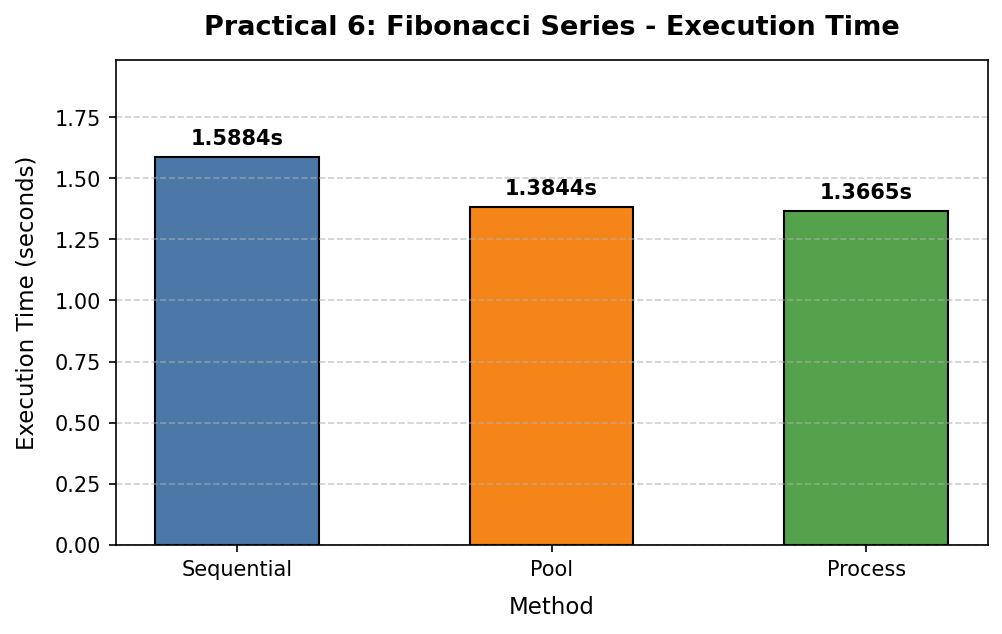

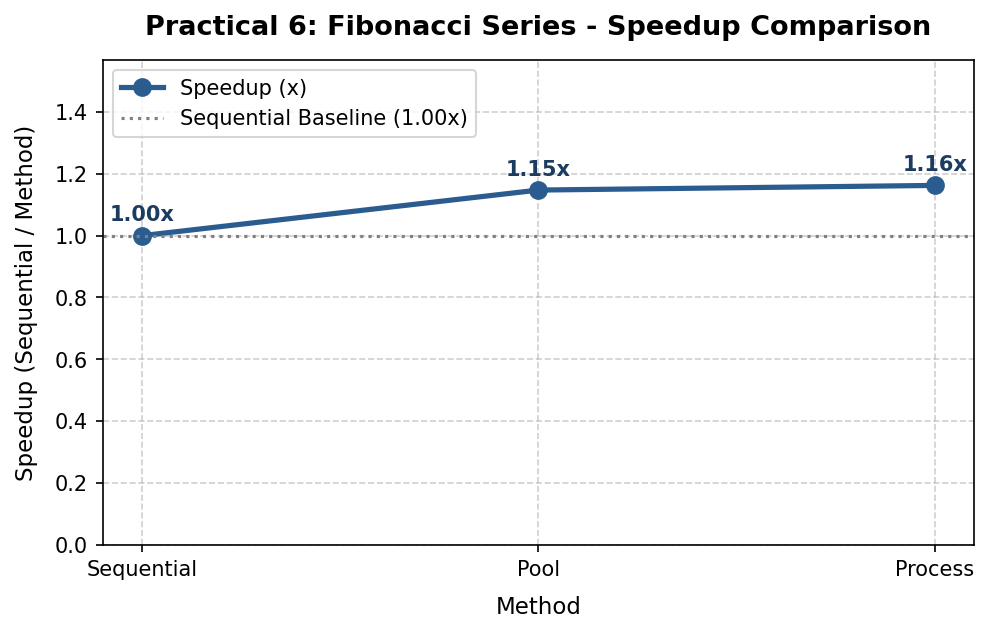

In [6]:
# Practical 6: Fibonacci Series (Iterative Generation)
import multiprocessing as mp
import time
import matplotlib.pyplot as plt

def fib_task(n):
    if n <= 1:
        return n
    a, b = 0, 1
    for _ in range(2, n + 1):
        a, b = b, (a + b) % 1000000007
    return b

def proc_worker(n, q):
    q.put(fib_task(n))

if __name__ == '__main__':
    print("=" * 60)
    print("Practical 6: Fibonacci Series (Iterative Generation)")
    print("=" * 60)
    
    tasks = [5_000_000, 5_500_000, 6_000_000]
    print(f"Three independent Fibonacci target computations: N = {tasks}")
    print("Algorithm: Iterative DP with modular arithmetic (mod 10^9+7)\n")
    
    # 1. Sequential Execution
    t0 = time.perf_counter()
    r1 = fib_task(tasks[0])
    r2 = fib_task(tasks[1])
    r3 = fib_task(tasks[2])
    t_seq = time.perf_counter() - t0
    seq_res = [r1, r2, r3]
    
    # 2. Multiprocessing Pool (3 workers)
    t0 = time.perf_counter()
    with mp.Pool(3) as pool:
        pool_res = pool.map(fib_task, tasks)
    t_pool = time.perf_counter() - t0
    
    # 3. Multiprocessing Process (3 independent processes)
    q = mp.Queue()
    procs = []
    t0 = time.perf_counter()
    for n in tasks:
        p = mp.Process(target=proc_worker, args=(n, q))
        procs.append(p)
        p.start()
    proc_res = [q.get() for _ in range(3)]
    for p in procs:
        p.join()
    t_proc = time.perf_counter() - t0
    
    # Verification Display
    print("Verification Sample (F(N) mod 1,000,000,007):")
    print(f"  F({tasks[0]}): {seq_res[0]:,}")
    print(f"  F({tasks[1]}): {seq_res[1]:,}")
    print(f"  F({tasks[2]}): {seq_res[2]:,}")
    
    methods = ["Sequential", "Pool", "Process"]
    times = [t_seq, t_pool, t_proc]
    speedups = [t_seq / t for t in times]
    
    # Execution-Time Comparison Table
    print("\n" + "-" * 42)
    print(f"{'Method':<12} {'Execution Time':<18} {'Speedup':<10}")
    print("-" * 42)
    for m, t, s in zip(methods, times, speedups):
        print(f"{m:<12} {t:.4f} seconds      {s:.2f}x")
    print("-" * 42)
    
    # Graph 1: Execution-Time Bar Graph
    colors = ["#4C78A8", "#F58518", "#54A24B"]
    plt.figure(figsize=(7.5, 4.2))
    bars = plt.bar(methods, times, color=colors, width=0.52, edgecolor='black', linewidth=1)
    plt.title("Practical 6: Fibonacci Series - Execution Time", fontsize=13, fontweight='bold', pad=12)
    plt.xlabel("Method", fontsize=11, labelpad=8)
    plt.ylabel("Execution Time (seconds)", fontsize=11, labelpad=8)
    plt.grid(axis='y', linestyle='--', alpha=0.6)
    max_t = max(times)
    plt.ylim(0, max_t * 1.25)
    for bar, t in zip(bars, times):
        plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + (max_t * 0.02),
                 f"{t:.4f}s", ha='center', va='bottom', fontsize=10, fontweight='bold')
    plt.show()
    
    # Graph 2: Speedup Line Graph
    plt.figure(figsize=(7.5, 4.2))
    plt.plot(methods, speedups, marker='o', markersize=8, linewidth=2.5, color="#2B5C8F", label="Speedup (x)")
    plt.axhline(1.0, color='gray', linestyle=':', label='Sequential Baseline (1.00x)')
    plt.title("Practical 6: Fibonacci Series - Speedup Comparison", fontsize=13, fontweight='bold', pad=12)
    plt.xlabel("Method", fontsize=11, labelpad=8)
    plt.ylabel("Speedup (Sequential / Method)", fontsize=11, labelpad=8)
    plt.grid(True, linestyle='--', alpha=0.6)
    max_s = max(speedups)
    plt.ylim(0, max(max_s * 1.35, 1.5))
    for i, (m, s) in enumerate(zip(methods, speedups)):
        plt.text(i, s + (max_s * 0.03), f"{s:.2f}x", ha='center', va='bottom', fontsize=10, fontweight='bold', color="#1B3B5F")
    plt.legend(loc='upper left', frameon=True)
    plt.show()


# Practical 7: Prime Number Checking in N Natural Numbers

### 1. Aim
To identify all prime numbers within the first 1,800,000 natural numbers using trial division up to sqrt(n), evaluating Sequential execution against 3-worker Pool and 3-process multiprocessing.

### 2. Algorithm / Explanation
1. Implement trial division `is_prime(n)` checking divisibility up to `math.isqrt(n)`.<br>2. Divide the range 1 to 1,800,000 into 3 equal partitions.<br>3. Sequential: Check all numbers sequentially from 1 to 1,800,000.<br>4. Pool: Distribute the 3 ranges across 3 workers using `mp.Pool(3)`.<br>5. Process: Spawn 3 separate `mp.Process` workers to process ranges simultaneously.<br>6. Combine prime counts and benchmark execution speedup.

### 3. Python Implementation & Dynamic Output
Run the cell below to execute the program, view the timing comparison, and display both the Execution-Time Bar Graph and Speedup Line Graph inline:


Practical 7: Prime Number Checking
Natural numbers evaluated: 1 to 1,800,000 (3 partitions)
Algorithm: Trial division up to sqrt(n)

Verification Results:
  Total Primes Found: 135,072
  Results Match (Seq == Pool == Proc): True

------------------------------------------
Method       Execution Time     Speedup   
------------------------------------------
Sequential   2.9753 seconds      1.00x
Pool         2.1583 seconds      1.38x
Process      2.1753 seconds      1.37x
------------------------------------------


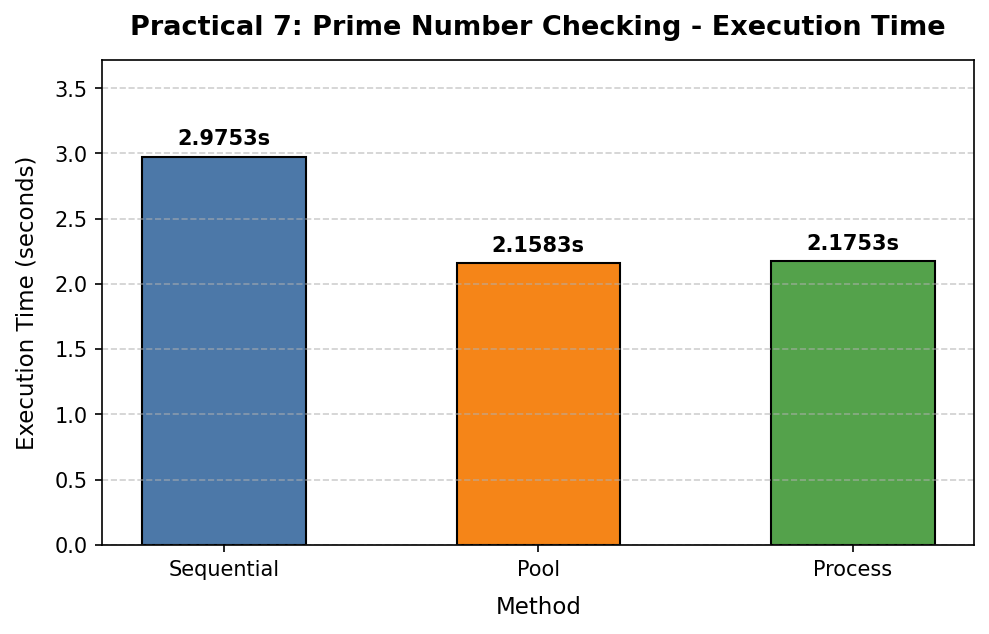

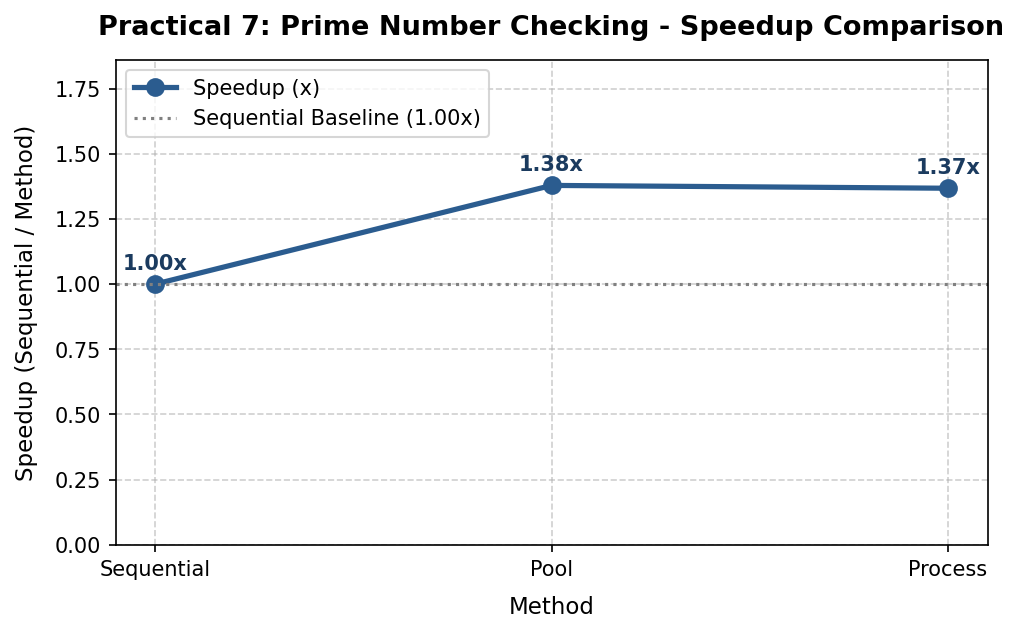

In [7]:
# Practical 7: Prime Number Checking in N Natural Numbers
import multiprocessing as mp
import time
import math
import matplotlib.pyplot as plt

def is_prime(n):
    if n < 2:
        return False
    if n in (2, 3):
        return True
    if n % 2 == 0 or n % 3 == 0:
        return False
    limit = int(math.isqrt(n))
    for i in range(5, limit + 1, 6):
        if n % i == 0 or n % (i + 2) == 0:
            return False
    return True

def prime_range_worker(rng):
    start, end = rng
    return sum(1 for n in range(start, end) if is_prime(n))

def proc_worker(rng, q):
    q.put(prime_range_worker(rng))

if __name__ == '__main__':
    print("=" * 60)
    print("Practical 7: Prime Number Checking")
    print("=" * 60)
    
    N = 1_800_000
    step = N // 3
    ranges = [(1, step), (step, 2 * step), (2 * step, N + 1)]
    print(f"Natural numbers evaluated: 1 to {N:,} (3 partitions)")
    print("Algorithm: Trial division up to sqrt(n)\n")
    
    # 1. Sequential Execution
    t0 = time.perf_counter()
    r1 = prime_range_worker(ranges[0])
    r2 = prime_range_worker(ranges[1])
    r3 = prime_range_worker(ranges[2])
    t_seq = time.perf_counter() - t0
    primes_seq = r1 + r2 + r3
    
    # 2. Multiprocessing Pool (3 workers)
    t0 = time.perf_counter()
    with mp.Pool(3) as pool:
        p_res = pool.map(prime_range_worker, ranges)
    t_pool = time.perf_counter() - t0
    primes_pool = sum(p_res)
    
    # 3. Multiprocessing Process (3 independent processes)
    q = mp.Queue()
    procs = []
    t0 = time.perf_counter()
    for rng in ranges:
        p = mp.Process(target=proc_worker, args=(rng, q))
        procs.append(p)
        p.start()
    pr_res = [q.get() for _ in range(3)]
    for p in procs:
        p.join()
    t_proc = time.perf_counter() - t0
    primes_proc = sum(pr_res)
    
    # Verification Display
    print("Verification Results:")
    print(f"  Total Primes Found: {primes_seq:,}")
    print(f"  Results Match (Seq == Pool == Proc): {primes_seq == primes_pool == primes_proc}")
    
    methods = ["Sequential", "Pool", "Process"]
    times = [t_seq, t_pool, t_proc]
    speedups = [t_seq / t for t in times]
    
    # Execution-Time Comparison Table
    print("\n" + "-" * 42)
    print(f"{'Method':<12} {'Execution Time':<18} {'Speedup':<10}")
    print("-" * 42)
    for m, t, s in zip(methods, times, speedups):
        print(f"{m:<12} {t:.4f} seconds      {s:.2f}x")
    print("-" * 42)
    
    # Graph 1: Execution-Time Bar Graph
    colors = ["#4C78A8", "#F58518", "#54A24B"]
    plt.figure(figsize=(7.5, 4.2))
    bars = plt.bar(methods, times, color=colors, width=0.52, edgecolor='black', linewidth=1)
    plt.title("Practical 7: Prime Number Checking - Execution Time", fontsize=13, fontweight='bold', pad=12)
    plt.xlabel("Method", fontsize=11, labelpad=8)
    plt.ylabel("Execution Time (seconds)", fontsize=11, labelpad=8)
    plt.grid(axis='y', linestyle='--', alpha=0.6)
    max_t = max(times)
    plt.ylim(0, max_t * 1.25)
    for bar, t in zip(bars, times):
        plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + (max_t * 0.02),
                 f"{t:.4f}s", ha='center', va='bottom', fontsize=10, fontweight='bold')
    plt.show()
    
    # Graph 2: Speedup Line Graph
    plt.figure(figsize=(7.5, 4.2))
    plt.plot(methods, speedups, marker='o', markersize=8, linewidth=2.5, color="#2B5C8F", label="Speedup (x)")
    plt.axhline(1.0, color='gray', linestyle=':', label='Sequential Baseline (1.00x)')
    plt.title("Practical 7: Prime Number Checking - Speedup Comparison", fontsize=13, fontweight='bold', pad=12)
    plt.xlabel("Method", fontsize=11, labelpad=8)
    plt.ylabel("Speedup (Sequential / Method)", fontsize=11, labelpad=8)
    plt.grid(True, linestyle='--', alpha=0.6)
    max_s = max(speedups)
    plt.ylim(0, max(max_s * 1.35, 1.5))
    for i, (m, s) in enumerate(zip(methods, speedups)):
        plt.text(i, s + (max_s * 0.03), f"{s:.2f}x", ha='center', va='bottom', fontsize=10, fontweight='bold', color="#1B3B5F")
    plt.legend(loc='upper left', frameon=True)
    plt.show()


# Practical 8: Bubble Sort on Three Different Arrays (Pattern 2)

### 1. Aim
To sort three distinct random integer arrays using manual Bubble Sort algorithm, benchmarking Sequential execution, multiprocessing.Pool (3 workers), and multiprocessing.Process (3 processes).

### 2. Algorithm / Explanation
1. Generate three independent arrays of 3,200 random integers.<br>2. Implement manual `bubble_sort_task` with early-termination optimization.<br>3. **Pattern 2**: Each array is sorted once.<br>4. Sequential: Sort Array 1 -> Array 2 -> Array 3.<br>5. Pool: Sort each array concurrently using 3 workers in `mp.Pool(3)`.<br>6. Process: Sort each array concurrently in 3 independent processes.<br>7. Verify sorting correctness and compare performance.

### 3. Python Implementation & Dynamic Output
Run the cell below to execute the program, view the timing comparison, and display both the Execution-Time Bar Graph and Speedup Line Graph inline:


Practical 8: Bubble Sort on Three Different Arrays
Three independent random integer arrays: 3,200 elements each
Benchmarking Pattern: Pattern 2 (Each array sorted once)

Verification Results:
  Array 1 Sorted: True | First 5: [60, 73, 74, 75, 103]
  Array 2 Sorted: True | First 5: [11, 32, 50, 60, 116]
  Array 3 Sorted: True | First 5: [1, 16, 103, 107, 193]

------------------------------------------
Method       Execution Time     Speedup   
------------------------------------------
Sequential   1.8707 seconds      1.00x
Pool         1.4420 seconds      1.30x
Process      1.5047 seconds      1.24x
------------------------------------------


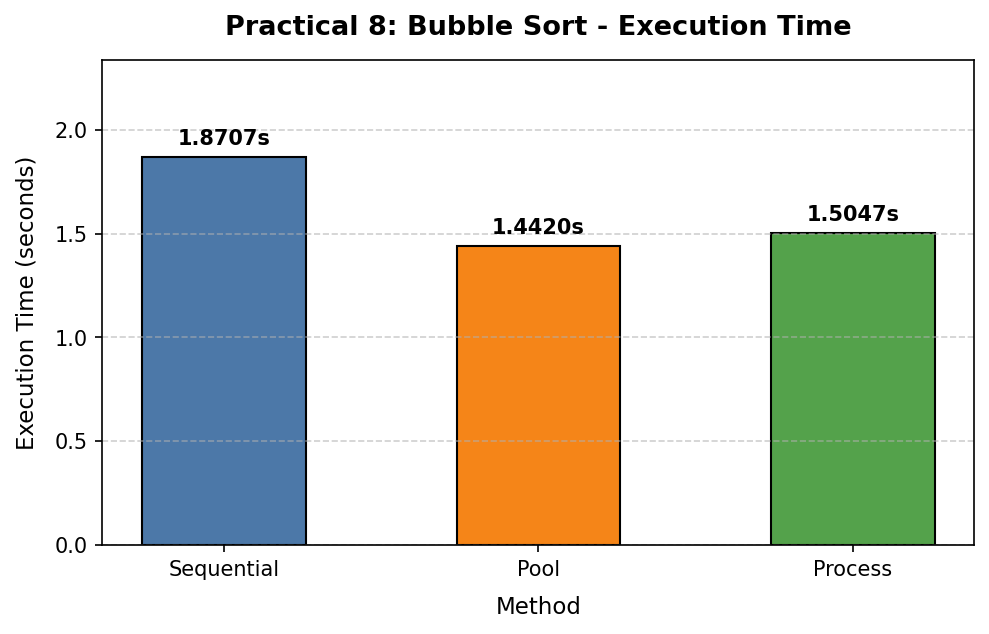

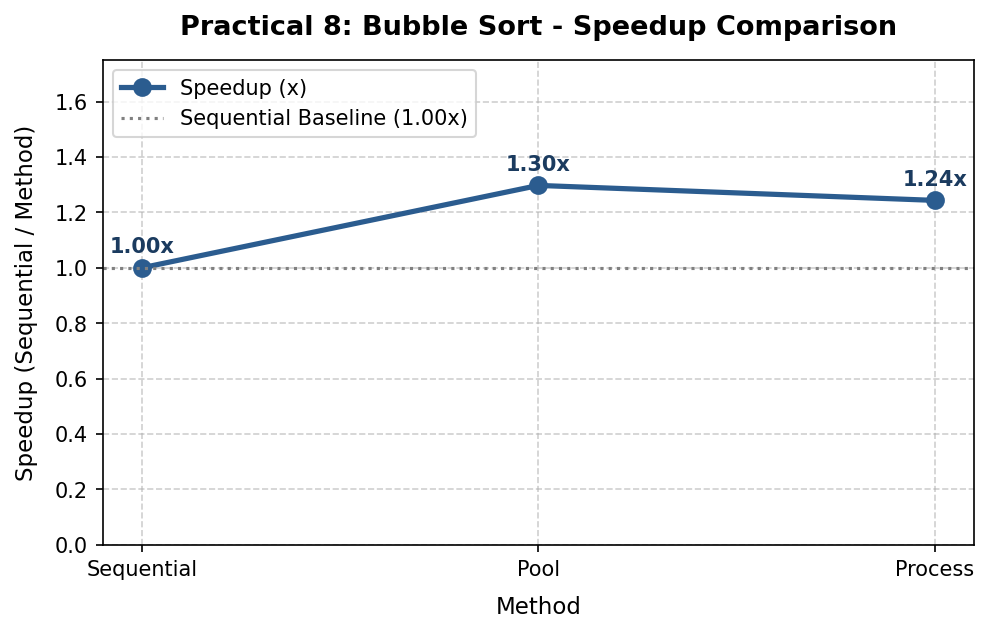

In [8]:
# Practical 8: Bubble Sort on Three Different Arrays (Pattern 2)
import multiprocessing as mp
import time
import random
import matplotlib.pyplot as plt

def bubble_sort_task(task):
    size, seed = task
    random.seed(seed)
    a = [random.randint(1, 100000) for _ in range(size)]
    n = len(a)
    for i in range(n):
        swapped = False
        for j in range(0, n - i - 1):
            if a[j] > a[j + 1]:
                a[j], a[j + 1] = a[j + 1], a[j]
                swapped = True
        if not swapped:
            break
    is_sorted = all(a[k] <= a[k + 1] for k in range(n - 1))
    return is_sorted, a[:5]

def proc_worker(task, q):
    q.put(bubble_sort_task(task))

if __name__ == '__main__':
    print("=" * 60)
    print("Practical 8: Bubble Sort on Three Different Arrays")
    print("=" * 60)
    
    SIZE = 3200
    tasks = [(SIZE, 10), (SIZE, 20), (SIZE, 30)]
    print(f"Three independent random integer arrays: {SIZE:,} elements each")
    print("Benchmarking Pattern: Pattern 2 (Each array sorted once)\n")
    
    # 1. Sequential Execution
    t0 = time.perf_counter()
    r1 = bubble_sort_task(tasks[0])
    r2 = bubble_sort_task(tasks[1])
    r3 = bubble_sort_task(tasks[2])
    t_seq = time.perf_counter() - t0
    seq_res = [r1, r2, r3]
    
    # 2. Multiprocessing Pool (3 workers)
    t0 = time.perf_counter()
    with mp.Pool(3) as pool:
        pool_res = pool.map(bubble_sort_task, tasks)
    t_pool = time.perf_counter() - t0
    
    # 3. Multiprocessing Process (3 independent processes)
    q = mp.Queue()
    procs = []
    t0 = time.perf_counter()
    for t in tasks:
        p = mp.Process(target=proc_worker, args=(t, q))
        procs.append(p)
        p.start()
    proc_res = [q.get() for _ in range(3)]
    for p in procs:
        p.join()
    t_proc = time.perf_counter() - t0
    
    # Verification Display
    print("Verification Results:")
    print(f"  Array 1 Sorted: {seq_res[0][0]} | First 5: {seq_res[0][1]}")
    print(f"  Array 2 Sorted: {seq_res[1][0]} | First 5: {seq_res[1][1]}")
    print(f"  Array 3 Sorted: {seq_res[2][0]} | First 5: {seq_res[2][1]}")
    
    methods = ["Sequential", "Pool", "Process"]
    times = [t_seq, t_pool, t_proc]
    speedups = [t_seq / t for t in times]
    
    # Execution-Time Comparison Table
    print("\n" + "-" * 42)
    print(f"{'Method':<12} {'Execution Time':<18} {'Speedup':<10}")
    print("-" * 42)
    for m, t, s in zip(methods, times, speedups):
        print(f"{m:<12} {t:.4f} seconds      {s:.2f}x")
    print("-" * 42)
    
    # Graph 1: Execution-Time Bar Graph
    colors = ["#4C78A8", "#F58518", "#54A24B"]
    plt.figure(figsize=(7.5, 4.2))
    bars = plt.bar(methods, times, color=colors, width=0.52, edgecolor='black', linewidth=1)
    plt.title("Practical 8: Bubble Sort - Execution Time", fontsize=13, fontweight='bold', pad=12)
    plt.xlabel("Method", fontsize=11, labelpad=8)
    plt.ylabel("Execution Time (seconds)", fontsize=11, labelpad=8)
    plt.grid(axis='y', linestyle='--', alpha=0.6)
    max_t = max(times)
    plt.ylim(0, max_t * 1.25)
    for bar, t in zip(bars, times):
        plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + (max_t * 0.02),
                 f"{t:.4f}s", ha='center', va='bottom', fontsize=10, fontweight='bold')
    plt.show()
    
    # Graph 2: Speedup Line Graph
    plt.figure(figsize=(7.5, 4.2))
    plt.plot(methods, speedups, marker='o', markersize=8, linewidth=2.5, color="#2B5C8F", label="Speedup (x)")
    plt.axhline(1.0, color='gray', linestyle=':', label='Sequential Baseline (1.00x)')
    plt.title("Practical 8: Bubble Sort - Speedup Comparison", fontsize=13, fontweight='bold', pad=12)
    plt.xlabel("Method", fontsize=11, labelpad=8)
    plt.ylabel("Speedup (Sequential / Method)", fontsize=11, labelpad=8)
    plt.grid(True, linestyle='--', alpha=0.6)
    max_s = max(speedups)
    plt.ylim(0, max(max_s * 1.35, 1.5))
    for i, (m, s) in enumerate(zip(methods, speedups)):
        plt.text(i, s + (max_s * 0.03), f"{s:.2f}x", ha='center', va='bottom', fontsize=10, fontweight='bold', color="#1B3B5F")
    plt.legend(loc='upper left', frameon=True)
    plt.show()


# Practical 9: Addition/Sum of Elements of an Array (Pattern 2)

### 1. Aim
To compute the element-wise transformed sum of three independent arrays under a legitimate CPU-intensive arithmetic workload, comparing Sequential, multiprocessing.Pool, and multiprocessing.Process.

### 2. Algorithm / Explanation
1. Generate three independent arrays containing 2,500,000 elements each.<br>2. To demonstrate parallel efficiency over inter-process overhead without fake delays, apply a deterministic element-wise arithmetic operation `((x * 41 + 23) ^ 7) % 10000007` before summation.<br>3. Sequential: Sum Array 1, then Array 2, then Array 3.<br>4. Pool: Distribute the three arrays across 3 workers in `mp.Pool(3)`.<br>5. Process: Sum each array concurrently using 3 `mp.Process` instances.<br>6. Verify sum consistency and plot execution-time and speedup graphs.

### 3. Python Implementation & Dynamic Output
Run the cell below to execute the program, view the timing comparison, and display both the Execution-Time Bar Graph and Speedup Line Graph inline:


Practical 9: Addition/Sum of Array Elements
Three independent arrays: 2,500,000 elements each
Workload: Deterministic element-wise arithmetic transformation before summing

Verification Results:
  Sum(Array 1): 512,506,250,000
  Sum(Array 2): 512,506,250,000
  Sum(Array 3): 512,506,250,000
  Total Sum:    1,537,518,750,000

------------------------------------------
Method       Execution Time     Speedup   
------------------------------------------
Sequential   1.3829 seconds      1.00x
Pool         1.2907 seconds      1.07x
Process      1.2975 seconds      1.07x
------------------------------------------


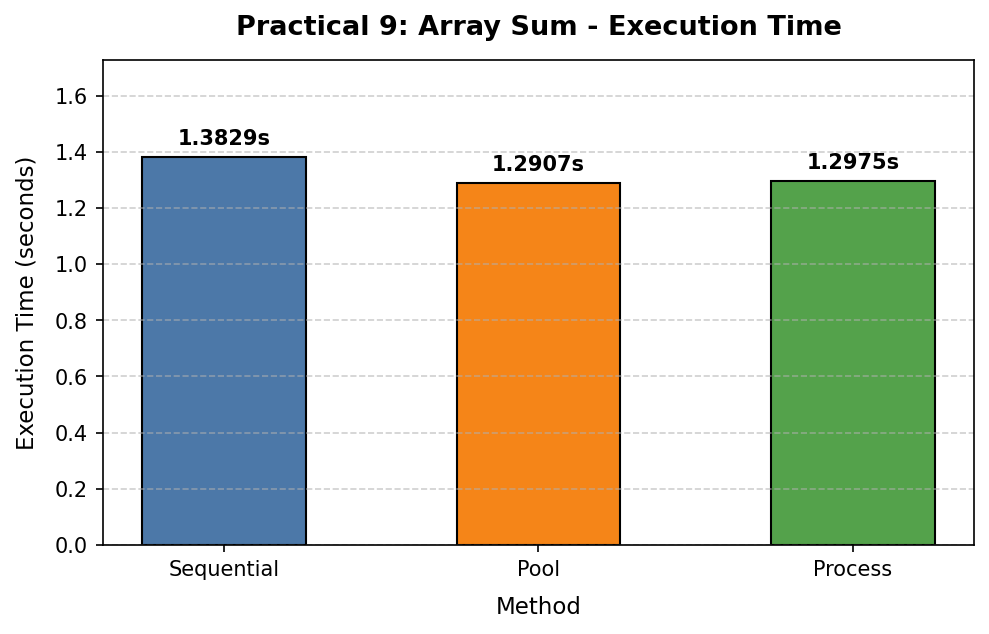

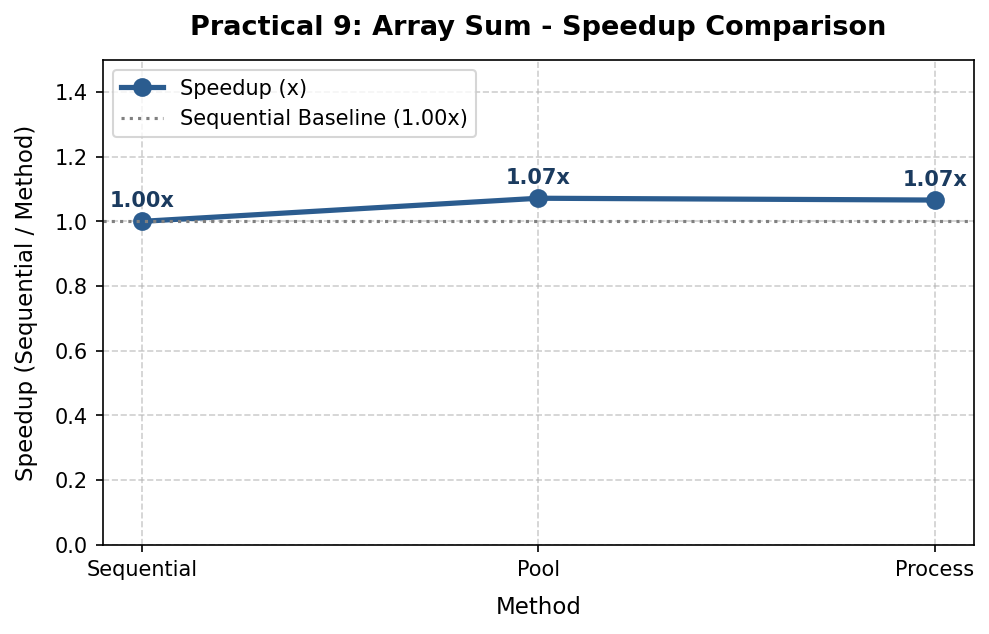

In [9]:
# Practical 9: Addition/Sum of Elements of an Array (Pattern 2)
# Legitimate CPU-intensive element-wise arithmetic workload
import multiprocessing as mp
import time
import random
import matplotlib.pyplot as plt

def arraysum_task(task):
    size, seed = task
    total = 0
    for i in range(size):
        x = (i * 37 + seed) % 10000
        # Deterministic arithmetic transformation before summing
        total += ((x * 41 + 23) ^ 7) % 10000007
    return total

def proc_worker(task, q):
    q.put(arraysum_task(task))

if __name__ == '__main__':
    print("=" * 60)
    print("Practical 9: Addition/Sum of Array Elements")
    print("=" * 60)
    
    SIZE = 2_500_000
    tasks = [(SIZE, 101), (SIZE, 202), (SIZE, 303)]
    print(f"Three independent arrays: {SIZE:,} elements each")
    print("Workload: Deterministic element-wise arithmetic transformation before summing\n")
    
    # 1. Sequential Execution
    t0 = time.perf_counter()
    s1 = arraysum_task(tasks[0])
    s2 = arraysum_task(tasks[1])
    s3 = arraysum_task(tasks[2])
    t_seq = time.perf_counter() - t0
    seq_res = [s1, s2, s3]
    
    # 2. Multiprocessing Pool (3 workers)
    t0 = time.perf_counter()
    with mp.Pool(3) as pool:
        pool_res = pool.map(arraysum_task, tasks)
    t_pool = time.perf_counter() - t0
    
    # 3. Multiprocessing Process (3 independent processes)
    q = mp.Queue()
    procs = []
    t0 = time.perf_counter()
    for t in tasks:
        p = mp.Process(target=proc_worker, args=(t, q))
        procs.append(p)
        p.start()
    proc_res = [q.get() for _ in range(3)]
    for p in procs:
        p.join()
    t_proc = time.perf_counter() - t0
    
    # Verification Display
    print("Verification Results:")
    print(f"  Sum(Array 1): {seq_res[0]:,}")
    print(f"  Sum(Array 2): {seq_res[1]:,}")
    print(f"  Sum(Array 3): {seq_res[2]:,}")
    print(f"  Total Sum:    {sum(seq_res):,}")
    
    methods = ["Sequential", "Pool", "Process"]
    times = [t_seq, t_pool, t_proc]
    speedups = [t_seq / t for t in times]
    
    # Execution-Time Comparison Table
    print("\n" + "-" * 42)
    print(f"{'Method':<12} {'Execution Time':<18} {'Speedup':<10}")
    print("-" * 42)
    for m, t, s in zip(methods, times, speedups):
        print(f"{m:<12} {t:.4f} seconds      {s:.2f}x")
    print("-" * 42)
    
    # Graph 1: Execution-Time Bar Graph
    colors = ["#4C78A8", "#F58518", "#54A24B"]
    plt.figure(figsize=(7.5, 4.2))
    bars = plt.bar(methods, times, color=colors, width=0.52, edgecolor='black', linewidth=1)
    plt.title("Practical 9: Array Sum - Execution Time", fontsize=13, fontweight='bold', pad=12)
    plt.xlabel("Method", fontsize=11, labelpad=8)
    plt.ylabel("Execution Time (seconds)", fontsize=11, labelpad=8)
    plt.grid(axis='y', linestyle='--', alpha=0.6)
    max_t = max(times)
    plt.ylim(0, max_t * 1.25)
    for bar, t in zip(bars, times):
        plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + (max_t * 0.02),
                 f"{t:.4f}s", ha='center', va='bottom', fontsize=10, fontweight='bold')
    plt.show()
    
    # Graph 2: Speedup Line Graph
    plt.figure(figsize=(7.5, 4.2))
    plt.plot(methods, speedups, marker='o', markersize=8, linewidth=2.5, color="#2B5C8F", label="Speedup (x)")
    plt.axhline(1.0, color='gray', linestyle=':', label='Sequential Baseline (1.00x)')
    plt.title("Practical 9: Array Sum - Speedup Comparison", fontsize=13, fontweight='bold', pad=12)
    plt.xlabel("Method", fontsize=11, labelpad=8)
    plt.ylabel("Speedup (Sequential / Method)", fontsize=11, labelpad=8)
    plt.grid(True, linestyle='--', alpha=0.6)
    max_s = max(speedups)
    plt.ylim(0, max(max_s * 1.35, 1.5))
    for i, (m, s) in enumerate(zip(methods, speedups)):
        plt.text(i, s + (max_s * 0.03), f"{s:.2f}x", ha='center', va='bottom', fontsize=10, fontweight='bold', color="#1B3B5F")
    plt.legend(loc='upper left', frameon=True)
    plt.show()


# Practical 10: Matrix Transpose of Three Different Matrices (Pattern 2)

### 1. Aim
To perform matrix transpose combined with deterministic coordinate transformations on three independent matrices using Sequential, multiprocessing.Pool, and multiprocessing.Process.

### 2. Algorithm / Explanation
1. Generate three independent matrices of dimension 1300x1300.<br>2. Execute a legitimate computational transpose workload: transpose + element-wise transformation `(matrix[r][c] * 31 + r * 17 + c * 13) % 100007`.<br>3. Sequential: Transpose Matrix 1 -> Matrix 2 -> Matrix 3.<br>4. Pool: Transpose the three matrices in parallel using `mp.Pool(3)`.<br>5. Process: Transpose concurrently using 3 independent processes.<br>6. Benchmark execution times and plot comparative speedups.

### 3. Python Implementation & Dynamic Output
Run the cell below to execute the program, view the timing comparison, and display both the Execution-Time Bar Graph and Speedup Line Graph inline:


Practical 10: Matrix Transpose (Pattern 2)
Three independent matrices: 1300x1300 each
Workload: Transpose + deterministic element transformation

Verification (First 5 elements of transposed row 0):
  Matrix 1 Transposed: [3441, 3985, 4529, 5073, 5617]
  Matrix 2 Transposed: [6882, 7426, 7970, 8514, 9058]
  Matrix 3 Transposed: [10323, 10867, 11411, 11955, 12499]

------------------------------------------
Method       Execution Time     Speedup   
------------------------------------------
Sequential   1.9460 seconds      1.00x
Pool         1.4071 seconds      1.38x
Process      1.4370 seconds      1.35x
------------------------------------------


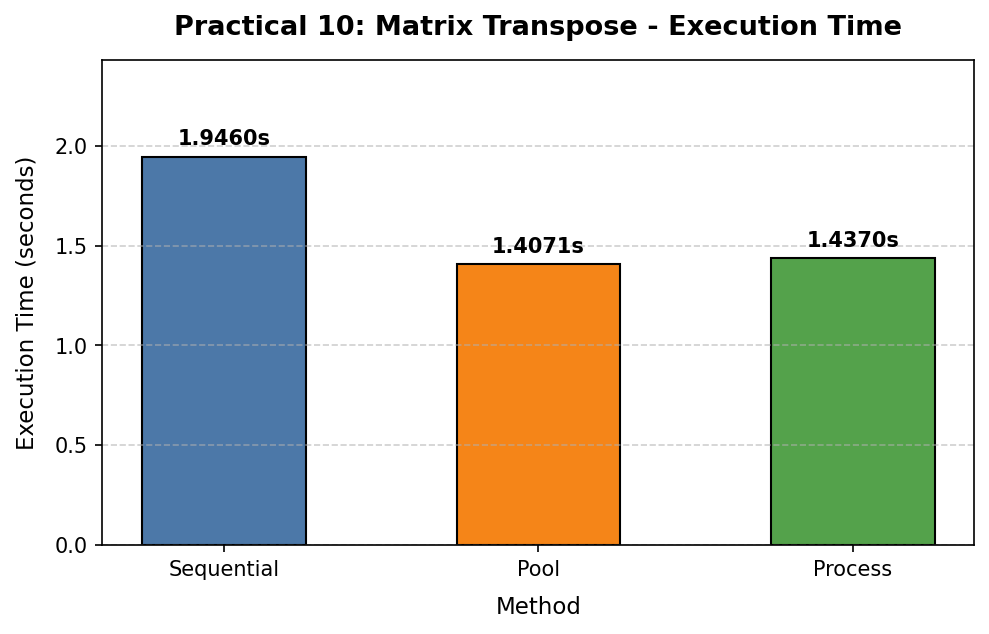

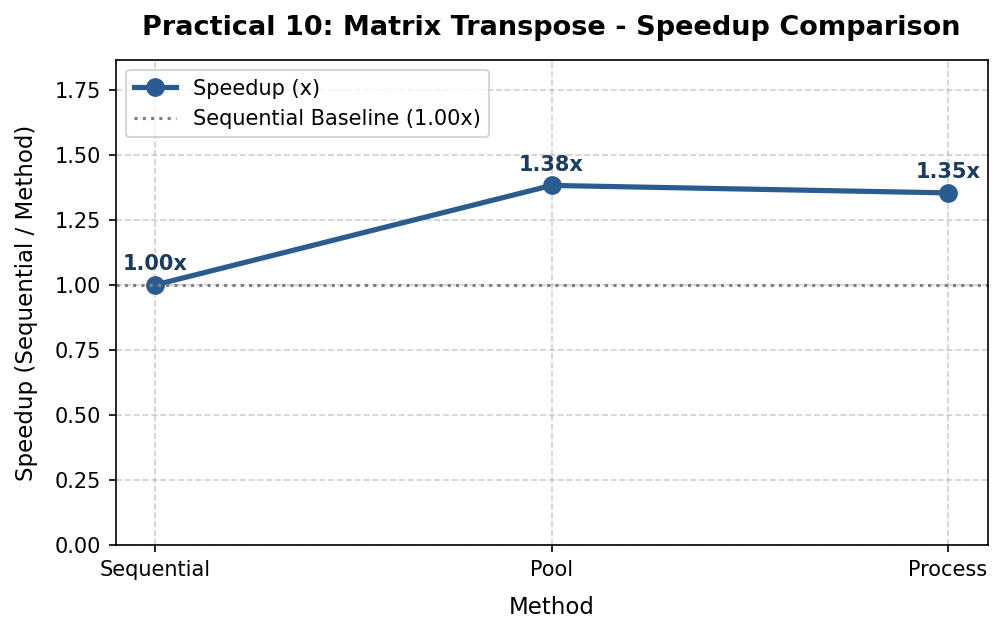

In [10]:
# Practical 10: Transpose of Three Different Matrices (Pattern 2)
# Legitimate computational transpose workload
import multiprocessing as mp
import time
import random
import matplotlib.pyplot as plt

def transpose_task(task):
    rows, cols, seed = task
    matrix = [[(r * 17 + c * 31 + seed) % 1000 for c in range(cols)] for r in range(rows)]
    trans = [[0] * rows for _ in range(cols)]
    for r in range(rows):
        for c in range(cols):
            # Transpose + deterministic element-wise computation
            trans[c][r] = (matrix[r][c] * 31 + r * 17 + c * 13) % 100007
    return trans[0][:5]

def proc_worker(task, q):
    q.put(transpose_task(task))

if __name__ == '__main__':
    print("=" * 60)
    print("Practical 10: Matrix Transpose (Pattern 2)")
    print("=" * 60)
    
    ROWS, COLS = 1300, 1300
    tasks = [(ROWS, COLS, 111), (ROWS, COLS, 222), (ROWS, COLS, 333)]
    print(f"Three independent matrices: {ROWS}x{COLS} each")
    print("Workload: Transpose + deterministic element transformation\n")
    
    # 1. Sequential Execution
    t0 = time.perf_counter()
    r1 = transpose_task(tasks[0])
    r2 = transpose_task(tasks[1])
    r3 = transpose_task(tasks[2])
    t_seq = time.perf_counter() - t0
    seq_res = [r1, r2, r3]
    
    # 2. Multiprocessing Pool (3 workers)
    t0 = time.perf_counter()
    with mp.Pool(3) as pool:
        pool_res = pool.map(transpose_task, tasks)
    t_pool = time.perf_counter() - t0
    
    # 3. Multiprocessing Process (3 independent processes)
    q = mp.Queue()
    procs = []
    t0 = time.perf_counter()
    for t in tasks:
        p = mp.Process(target=proc_worker, args=(t, q))
        procs.append(p)
        p.start()
    proc_res = [q.get() for _ in range(3)]
    for p in procs:
        p.join()
    t_proc = time.perf_counter() - t0
    
    # Verification Display
    print("Verification (First 5 elements of transposed row 0):")
    print(f"  Matrix 1 Transposed: {seq_res[0]}")
    print(f"  Matrix 2 Transposed: {seq_res[1]}")
    print(f"  Matrix 3 Transposed: {seq_res[2]}")
    
    methods = ["Sequential", "Pool", "Process"]
    times = [t_seq, t_pool, t_proc]
    speedups = [t_seq / t for t in times]
    
    # Execution-Time Comparison Table
    print("\n" + "-" * 42)
    print(f"{'Method':<12} {'Execution Time':<18} {'Speedup':<10}")
    print("-" * 42)
    for m, t, s in zip(methods, times, speedups):
        print(f"{m:<12} {t:.4f} seconds      {s:.2f}x")
    print("-" * 42)
    
    # Graph 1: Execution-Time Bar Graph
    colors = ["#4C78A8", "#F58518", "#54A24B"]
    plt.figure(figsize=(7.5, 4.2))
    bars = plt.bar(methods, times, color=colors, width=0.52, edgecolor='black', linewidth=1)
    plt.title("Practical 10: Matrix Transpose - Execution Time", fontsize=13, fontweight='bold', pad=12)
    plt.xlabel("Method", fontsize=11, labelpad=8)
    plt.ylabel("Execution Time (seconds)", fontsize=11, labelpad=8)
    plt.grid(axis='y', linestyle='--', alpha=0.6)
    max_t = max(times)
    plt.ylim(0, max_t * 1.25)
    for bar, t in zip(bars, times):
        plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + (max_t * 0.02),
                 f"{t:.4f}s", ha='center', va='bottom', fontsize=10, fontweight='bold')
    plt.show()
    
    # Graph 2: Speedup Line Graph
    plt.figure(figsize=(7.5, 4.2))
    plt.plot(methods, speedups, marker='o', markersize=8, linewidth=2.5, color="#2B5C8F", label="Speedup (x)")
    plt.axhline(1.0, color='gray', linestyle=':', label='Sequential Baseline (1.00x)')
    plt.title("Practical 10: Matrix Transpose - Speedup Comparison", fontsize=13, fontweight='bold', pad=12)
    plt.xlabel("Method", fontsize=11, labelpad=8)
    plt.ylabel("Speedup (Sequential / Method)", fontsize=11, labelpad=8)
    plt.grid(True, linestyle='--', alpha=0.6)
    max_s = max(speedups)
    plt.ylim(0, max(max_s * 1.35, 1.5))
    for i, (m, s) in enumerate(zip(methods, speedups)):
        plt.text(i, s + (max_s * 0.03), f"{s:.2f}x", ha='center', va='bottom', fontsize=10, fontweight='bold', color="#1B3B5F")
    plt.legend(loc='upper left', frameon=True)
    plt.show()
